# Homework 4 - Evaluation Metrics for Classification

Dataset: 2026 lead-scoring (`course_lead_scoring_2026.csv`). Target: `converted`.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

C:\Users\ACER\anaconda3\lib\site-packages\scipy\__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


## Dataset

Pakai file lokal dari `cohorts/2026/data/` jika ada, kalau tidak download dari GitHub.

In [2]:
local = '../cohorts/2026/data/course_lead_scoring_2026.csv'
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

data = local if os.path.exists(local) else url
df = pd.read_csv(data)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Data preparation

* Cek missing values
* Kategorikal -> `'NA'`, numerikal -> `0.0`

In [3]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
categorical = list(df.dtypes[df.dtypes == 'object'].index)
numerical = [c for c in df.columns if c not in categorical and c != 'converted']

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

categorical, numerical

(['lead_source', 'industry', 'employment_status', 'location'],
 ['annual_income',
  'number_of_courses_viewed',
  'interaction_count',
  'lead_score'])

Split data 60/20/20:

In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

## Question 1: ROC AUC feature importance

Pakai tiap variabel numerik sebagai score, hitung AUC di train. Jika AUC < 0.5, balik tandanya.

In [6]:
for c in ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    print('%25s: %.3f' % (c, auc))

               lead_score: 0.788
 number_of_courses_viewed: 0.723
        interaction_count: 0.765
            annual_income: 0.608


## Question 2: Training the model

In [7]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
round(roc_auc_score(y_val, y_pred), 3)

0.732

## Question 3: Precision and Recall

Hitung precision & recall untuk threshold 0.0 - 1.0 (step 0.01).

In [8]:
def confusion_matrix_dataframe(y_val, y_pred):
    scores = []

    thresholds = np.linspace(0, 1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)

        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()

        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()

        scores.append((t, tp, fp, fn, tn))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns=columns)

    return df_scores

df_scores = confusion_matrix_dataframe(y_val, y_pred)

df_scores['p'] = (df_scores.tp / (df_scores.tp + df_scores.fp)).fillna(0)
df_scores['r'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores[::10]

,threshold,tp,fp,fn,tn,p,r
0,0.0,586,414,0,0,0.586000,1.000000
10,0.1,586,414,0,0,0.586000,1.000000
20,0.2,586,414,0,0,0.586000,1.000000
30,0.3,586,403,0,11,0.592518,1.000000
40,0.4,573,362,13,52,0.612834,0.977816
50,0.5,531,294,55,120,0.643636,0.906143
60,0.6,457,190,129,224,0.706337,0.779863
70,0.7,311,82,275,332,0.791349,0.530717
80,0.8,139,23,447,391,0.858025,0.237201
90,0.9,19,1,567,413,0.950000,0.032423


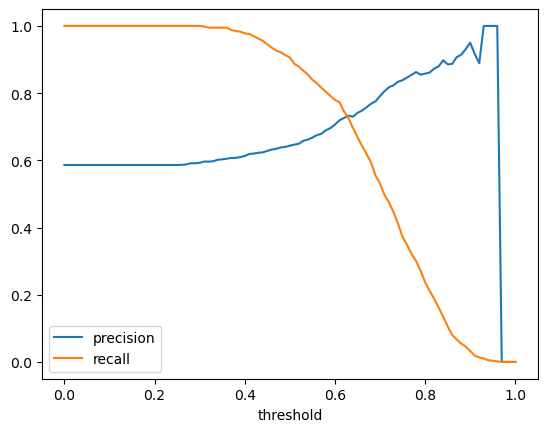

In [9]:
plt.plot(df_scores.threshold, df_scores.p, label='precision')
plt.plot(df_scores.threshold, df_scores.r, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.show()

In [10]:
# abaikan threshold di mana precision & recall sama-sama nol
df_pr = df_scores[(df_scores.p > 0) | (df_scores.r > 0)].copy()
df_pr['diff'] = (df_pr.p - df_pr.r).abs()
df_pr.loc[df_pr['diff'].idxmin(), ['threshold', 'p', 'r', 'diff']]

threshold    0.630000
p            0.732759
r            0.725256
diff         0.007503
Name: 63, dtype: float64

## Question 4: F1 score

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

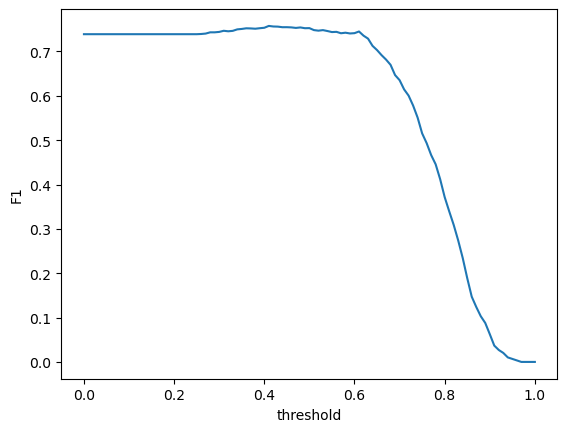

In [11]:
df_scores['f1'] = (2 * df_scores.p * df_scores.r / (df_scores.p + df_scores.r)).fillna(0)

plt.plot(df_scores.threshold, df_scores.f1)
plt.xlabel('threshold')
plt.ylabel('F1')
plt.show()

In [12]:
df_scores.loc[df_scores.f1.idxmax(), ['threshold', 'p', 'r', 'f1']]

threshold    0.410000
p            0.619048
r            0.976109
f1           0.757616
Name: 41, dtype: float64

## Question 5: 5-Fold CV

In [13]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model


def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [14]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_vl = df_full_train.iloc[val_idx]

    y_tr = df_tr.converted.values
    y_vl = df_vl.converted.values

    dv, model = train(df_tr, y_tr, C=1.0)
    y_pred = predict(df_vl, dv, model)

    scores.append(roc_auc_score(y_vl, y_pred))

print(np.round(scores, 3))
print('mean = %.3f, std = %.3f' % (np.mean(scores), np.std(scores)))

[0.731 0.73  0.736 0.741 0.721]
mean = 0.732, std = 0.007


## Question 6: Hyperparameter Tuning

In [15]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_vl = df_full_train.iloc[val_idx]

        y_tr = df_tr.converted.values
        y_vl = df_vl.converted.values

        dv, model = train(df_tr, y_tr, C=C)
        y_pred = predict(df_vl, dv, model)

        scores.append(roc_auc_score(y_vl, y_pred))

    print('C=%s: mean = %.3f, std = %.3f' % (C, np.mean(scores), np.std(scores)))

C=1e-06: mean = 0.617, std = 0.019
C=0.001: mean = 0.749, std = 0.010
C=1: mean = 0.732, std = 0.007


## Jawaban

| Question | Jawaban |
|---|---|
| Q1 - AUC tertinggi | `lead_score` (0.788) |
| Q2 - AUC validation | 0.732 |
| Q3 - Precision = Recall | 0.63 |
| Q4 - F1 maksimal | 0.41 |
| Q5 - Std 5-Fold CV | 0.007 |
| Q6 - C terbaik | 0.001 (mean 0.749) |